# HW9 Lab: Text Generation & HuggingFace Spaces 🚀🌐

<!-- lab-header:begin -->
**MIS 769 · Big Data Analytics for Business · Fall 2026**

**Points:** 40  |  **Due:** Sunday, November 8, 2026 at 10:00 PM Pacific

**Dr. Richard J. Young** · UNLV Lee Business School
<!-- lab-header:end -->

> **Why are we learning this?** Every lab so far ended inside a notebook. This one
> ends with a **public web application on the internet** that anyone — a recruiter, a
> hiring manager, your team — can open and use. The HuggingFace ecosystem is "the
> GitHub of AI": the **Hub** hosts 500K+ models, the **Pipeline API** gives you
> one-line inference, **Gradio** turns a Python function into a web UI, and **Spaces**
> hosts that UI for free. The transferable skill: **taking an ML capability from
> notebook to deployed product** — the last mile that most analysts never learn.

**How this lab works:** Parts 1–3 are a *working demo* — Runtime → Run all gives you
a complete, tested Gradio app inside Colab. Your job along the way: twist the decoding
knobs in the 🧪 Experiment cells until you can *feel* what temperature and top-p do.
Part 4 (deployment) is the one part that can't run itself — it needs YOUR HuggingFace
account. The 🎮 Playground turns the app into a generator for a domain you're
passionate about *before* you deploy, so the thing you ship is yours.

⏱️ **Honest effort warning:** this is the highest-effort lab of the course — budget
**6–8 hours**. Parts 1–3 give you a fully working app *locally in Colab* before
deployment starts; if deployment fights you, you still have a working app and most of
the points. Start early, not Sunday afternoon.


## Learning objectives

- Generate text with a small instruct model via the `transformers` Pipeline API
- Systematically explore temperature, top-p, top-k, and repetition penalty
- Build a Gradio interface with sliders wired to those parameters
- Deploy it as a public HuggingFace Space and ship the URL


## Setup

Model: **`Qwen/Qwen2.5-0.5B-Instruct`** — a 0.5B-parameter instruction-tuned model,
small enough for the free Colab CPU (a T4 GPU runtime makes it snappier: Runtime →
Change runtime type → T4). Small is the point: your deployed Space will run on a free
CPU, so we build with the model we'll ship.


In [1]:
!pip install -q transformers gradio huggingface_hub accelerate

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

from transformers import pipeline
generator = pipeline("text-generation", model=MODEL_ID)
print(f"✅ {MODEL_ID} loaded")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

✅ Qwen/Qwen2.5-0.5B-Instruct loaded


## Part 1: Text Generation (8 pts)

Under the hood (from lecture): the tokenizer turns your prompt into token IDs, the
model outputs a probability for every token in its vocabulary, a **decoding strategy**
picks one, and the loop repeats — generation is sequential, one token at a time.
Instruct models expect a *chat format* (a list of role/content messages), so we wrap
the pipeline in a helper. Two details worth reading in the code: the pipeline returns
the whole message list in `out[0]["generated_text"]`, so the reply is the *last*
message's `content`; and we always use `max_new_tokens` (how many tokens to
*generate*), never the deprecated `max_length` (which counts prompt + output together
and truncates confusingly).


In [2]:
def generate(prompt, max_new_tokens=200, **params):
    """Run one chat-formatted prompt through the pipeline, return the reply text."""
    messages = [{"role": "user", "content": prompt}]
    out = generator(messages, max_new_tokens=max_new_tokens, **params)
    return out[0]["generated_text"][-1]["content"]

print(generate("Write a two-sentence marketing tagline for a coffee subscription service."))

"Experience the art of caffeine in every sip with our expertly curated blends and unparalleled convenience."


In [12]:
# Try a few business-flavored generation tasks. Your outputs will vary — that's
# the nature of sampling, and exactly what Part 2 investigates.
business_prompts = [
     "Write a three-bullet executive summary for a retail company "
    "called TechMart. The audience is senior executives considering "
    "AI chatbots for customer service. Focus on cost savings, "
    "customer satisfaction, and operational efficiency. "
    "Do not use the words 'revolutionary', 'innovative', or 'game-changing'.",
]
for p in business_prompts:
    print("PROMPT:", p)
    print(generate(p, max_new_tokens=30))
    print("-" * 70)

PROMPT: Write a three-bullet executive summary for a retail company called TechMart. The audience is senior executives considering AI chatbots for customer service. Focus on cost savings, customer satisfaction, and operational efficiency. Do not use the words 'revolutionary', 'innovative', or 'game-changing'.
Title: A Strategic Approach to Enhancing Customer Service with AI Chatbots in TechMart

TechMart, a leading retailer, has decided to leverage AI
----------------------------------------------------------------------


### 🧪 Experiment

- Run the tagline prompt three times in a row. How different are the three outputs — and what does that mean for a business that needs *reproducible* copy?
- Cut `max_new_tokens` to 30 on the executive-summary prompt. Does the model finish early or get chopped mid-sentence? (That difference matters for UX.)
- Make one prompt drastically more specific (brand name, audience, banned words). How much of "model quality" is really prompt quality?


**In a markdown cell:** pick the best and worst output above. What did the model
do well, and where does a 0.5B model show its size (generic phrasing, factual wobble,
repetition)?


## Part 2: Parameter Exploration (8 pts)

Decoding parameters are the **creativity–accuracy dial** from lecture:

| Parameter | What it does | Low value | High value |
|---|---|---|---|
| `temperature` | Rescales token probabilities | safe, repetitive | creative, chaotic |
| `top_p` | Sample only from tokens covering p of probability mass | conservative | diverse |
| `top_k` | Sample only from the k most likely tokens | focused | diverse |
| `repetition_penalty` | Punishes reusing tokens | loops possible | may avoid needed words |

These matter commercially: a legal-summary bot wants temperature ≈ 0.2; a slogan
brainstormer wants ≈ 1.0+. Same model, different product.


In [4]:
# One prompt, three temperatures — greedy vs. mild vs. wild.
probe = "Write an opening line for an email announcing a 10% price increase to customers."

for temp in [0.2, 0.7, 1.3]:
    print(f"--- temperature={temp} ---")
    print(generate(probe, max_new_tokens=60, do_sample=True, temperature=temp))
    print()

--- temperature=0.2 ---
Dear valued customers,

We are excited to announce that from [insert date] onwards, we will be offering a 10% discount on all our products and services. This is a significant opportunity to reduce costs and improve profitability.

At Alibaba Cloud, we believe in providing exceptional value to our customers.

--- temperature=0.7 ---
Dear valued customer,

We're excited to announce that from this quarter, our pricing will be increased by 10%, bringing it closer to our current competitive position.

Please note that this is a temporary adjustment and we appreciate your understanding as we work to maintain the integrity of our prices while ensuring continued profitability

--- temperature=1.3 ---
"🚀 Hurry up! With today's big 10% discount offer, it's the perfect time to upgrade your favorite product and get a fantastic deal!"



In [5]:
# Systematic sweep over the other three parameters, one at a time,
# holding everything else fixed (do_sample=True, temperature=0.7).
sweeps = {
    "top_p": [0.5, 0.9, 1.0],
    "top_k": [5, 50, 0],               # 0 = disabled
    "repetition_penalty": [1.0, 1.3, 1.8],
}
for param, values in sweeps.items():
    print("=" * 70)
    for v in values:
        print(f"--- {param}={v} ---")
        print(generate(probe, max_new_tokens=60, do_sample=True,
                       temperature=0.7, **{param: v}))
        print()

--- top_p=0.5 ---
Dear valued customers,

We're excited to announce that we have decided to offer a 10% discount on all of your purchases starting today! This is just one more step in our commitment to providing you with the best value possible.

With this new pricing policy, you'll be able to enjoy significant

--- top_p=0.9 ---
"Exciting news! Our 10% discount on your next purchase is now available, and we're thrilled to offer this substantial price reduction for our loyal customer base!"

--- top_p=1.0 ---
Dear valued customers,

We are thrilled to announce that our pricing strategy is evolving with the latest market trends and consumer demands. As part of this change, we have decided to offer you a 10% discount on your purchases.

This significant reduction in prices not only enhances competitiveness but also fosters loyalty

--- top_k=5 ---
Dear valued customers,

As we look forward to another year of success and growth together, we're excited to announce that our current pricing 

In [13]:

prompt = "Write an opening line for an email announcing a 10% price increase to customers."

for temp in [0.1, 1.5]:
    print(f"\nTEMPERATURE: {temp}")
    for run in range(3):
        print(f"Run {run + 1}:")
        print(generate(
            prompt,
            max_new_tokens=80,
            do_sample=True,
            temperature=temp
        ))
        print("-" * 60)



TEMPERATURE: 0.1
Run 1:
Dear valued customers,

We are excited to announce that we have made the bold decision to increase our prices by 10%. This is not just about making money; it's about ensuring that you can afford our products and services without compromising on quality or value.

As we look forward to continuing to serve you with the best in everything from electronics to home appliances, we believe this price increase will help us
------------------------------------------------------------
Run 2:
Dear valued customers,

We are excited to announce that we have made the bold decision to increase our prices by 10%. This is not just about making money; it's about ensuring that you can afford our products and services without compromising on quality or value.

As we look forward to continuing to serve you with the best in everything from our products to our customer support, we want to make sure that
------------------------------------------------------------
Run 3:
Dear valued c

In [17]:

prompt = "Write an opening line for an email announcing a 10% price increase to customers."

for temp in [0.1, 1.5]:
    print(f"\nTEMPERATURE: {temp}")
    for run in range(3):
        print(f"Run {run + 1}:")
        print(generate(
            prompt,
            max_new_tokens=80,
            do_sample=True,
            temperature=temp
        ))
        print("-" * 60)



TEMPERATURE: 0.1
Run 1:
Dear valued customers,

We are excited to announce that we have made the bold decision to increase our prices by 10%. This is not just about making money; it's about ensuring that you can afford our products and services without compromising on quality or value.

As we look forward to continuing to serve you with the best in everything from our products to our customer support, please know that this price increase
------------------------------------------------------------
Run 2:
Dear valued customers,

We are excited to announce that we have decided to offer a 10% discount on all of your purchases this month. This is a great opportunity to save money and enjoy the best deals available.

Please feel free to contact us at [insert contact information] or visit our website to learn more about our new pricing policy.

Thank you for choosing us as your preferred retailer. We
------------------------------------------------------------
Run 3:
Dear valued customers,


In [14]:
# turn off repetition penalty = 1.0
prompt = "List reasons to visit Las Vegas."

print(generate(
    prompt,
    max_new_tokens=200,
    do_sample=True,
    temperature=0.2,
    repetition_penalty=1.0
))


Las Vegas is a popular tourist destination known for its diverse attractions, cultural experiences, and luxurious accommodations. Here are some reasons why people visit Las Vegas:

1. Cultural and Artistic Experience: Las Vegas is home to a vibrant arts scene, with numerous museums, galleries, and theaters. Visitors can explore the city's rich history and cultural heritage through its museums, galleries, and theaters.

2. Outdoor Activities: Las Vegas offers a wide range of outdoor activities, including water parks, casinos, and outdoor attractions like the Las Vegas Strip, which is known for its neon lights, water slides, and water parks.

3. Entertainment: Las Vegas is famous for its casinos, which offer a wide range of entertainment options, including poker rooms, blackjack, and slot machines. Visitors can also enjoy live music, dance performances, and other forms of entertainment.

4. Outdoor Sports: Las Vegas is home to several outdoor sports venues, including the Las Vegas Strip,

In [15]:

prompt = "Congratulations — you've reinvented greedy decoding."

for run in range(3):
    print(f"Run {run + 1}:")
    print(generate(
        prompt,
        max_new_tokens=60,
        do_sample=False,
        top_k=1
    ))
    print("-" * 60)


[transformers] The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Run 1:
Thank you! I'm glad to see that my approach to decoding has been appreciated. If you have any more questions or need further clarification on any topic, feel free to ask. I'm here to help with whatever information you might require.
------------------------------------------------------------
Run 2:
Thank you! I'm glad to see that my approach to decoding has been appreciated. If you have any more questions or need further clarification on any topic, feel free to ask. I'm here to help with whatever information you might require.
------------------------------------------------------------
Run 3:
Thank you! I'm glad to see that my approach to decoding has been appreciated. If you have any more questions or need further clarification on any topic, feel free to ask. I'm here to help with whatever information you might require.
------------------------------------------------------------


In [18]:

prompt = "Write an opening line for an email announcing a 10% price increase to customers."

tests = [
    ("top_p", 0.5),
    ("top_p", 1.0),
    ("top_k", 5),
    ("repetition_penalty", 1.8)
]

for parameter, value in tests:
    print(f"\n{parameter} = {value}")

    result = generate(
        prompt,
        max_new_tokens=80,
        do_sample=True,
        temperature=0.7,
        **{parameter: value}
    )

    print(result)
    print("-" * 60)



top_p = 0.5
Dear valued customers,

We are excited to announce that from [insert date] onwards, we will be offering a 10% discount on all our products and services. This generous offer is designed to make your shopping experience even more enjoyable and convenient.

Thank you for choosing us as your preferred partner in the world of digital solutions. We look forward to continuing to serve you with the best possible service and
------------------------------------------------------------

top_p = 1.0
Dear valued customer,

We sincerely apologize for any inconvenience this pricing change may have caused and are grateful for your patience during this time. We understand that our prices could be slightly higher due to the recent market conditions. However, we would like to offer you an unexpected discount of just 10% on all items in our store.

Thank you for choosing us as your preferred shopping destination. We look forward
------------------------------------------------------------

t

### 🧪 Experiment

- Run temperature 0.1 vs 1.5 on the SAME prompt, side by side, three times each. At 0.1 the runs should be near-identical; at 1.5, chaos. Which would you ship in a customer-facing email tool?
- Set `repetition_penalty=1.0` (i.e., off) with `temperature=0.2` and `max_new_tokens=200` on a listy prompt like "List reasons to visit Las Vegas." — and watch it loop. Now you know what that slider is protecting you from.
- Try `top_k=1`. Congratulations — you've reinvented greedy decoding. Why does the output no longer change between runs, even with do_sample=True?


### Fill in your comparison table

Copy this into a markdown cell and fill it from YOUR outputs (never invent rows —
the point is observed behavior):

| Parameter | Value | What the output looked like | When would a business want this? |
|---|---|---|---|
| temperature | 0.2 |Produced structured email, incorrectly described a 10% discount instead of increase. | Useful for predictable business communication, but accuracy would need work. |
| temperature | 1.3 |Created unrelated promotional email.  | This can be useful for brainstorming, though also misleading for select customer groups.  |
| top_p | 0.5 | 2 out of 3 outputs correctly communicated the 10% increase. | Useful for more focused responses |
| top_p | 1.0 |  Acknowledged pricing changes but incorrectly introduced a 10% discount. |  Useful when businesses want more creative responses. |
| top_k | 5 | Identified the 10% price increase but used repetitive language. | This would be useful for more controlled language |
| repetition_penalty | 1.8 | Avoided obvious repetition but introduced an unrelated 35% discount and awkward wording. |  Useful for reducing repetitive language |

This table is the raw material for **Q1** and your Part 5 writeup.


## Part 3: Gradio Interface (10 pts)

Gradio (from lecture: "Spaces: from notebook to web app") turns a Python function
into a web UI — you declare the inputs and outputs, it builds the page. We wire
sliders to the exact parameters you just explored, so any user can feel the
creativity dial without reading a line of code. **This same `app_fn` will be your
deployed app in Part 4 — get it right here where debugging is easy.**


In [20]:
import gradio as gr

def app_fn(prompt, max_new_tokens, temperature, top_p, repetition_penalty):
    return generate(prompt,
                    max_new_tokens=int(max_new_tokens),
                    do_sample=True,
                    temperature=float(temperature),
                    top_p=float(top_p),
                    repetition_penalty=float(repetition_penalty))

demo = gr.Interface(
    fn=app_fn,
    inputs=[
        gr.Textbox(lines=3, label="Prompt",
                   value="Create a three sentence mission statement for the analytical startup business."),
        gr.Slider(20, 500, value=150, step=10, label="Max new tokens"),
        gr.Slider(0.1, 2.0, value=0.7, step=0.1, label="Temperature (creativity)"),
        gr.Slider(0.1, 1.0, value=0.9, step=0.05, label="Top-p (nucleus sampling)"),
        gr.Slider(1.0, 2.0, value=1.1, step=0.1, label="Repetition penalty"),
    ],
    outputs=gr.Textbox(lines=8, label="Generated text"),
    title="Building IQ - AI for Energy Analytics",
    description="Small instruct model with adjustable decoding parameters. Slide temperature up and watch it get weird.",
)
demo.launch(share=True)   # share=True gives a temporary public link from Colab

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4f6a44f09226ed18ba.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



### Gradio Application Experiment

#### Test 1: Temperature 0.2
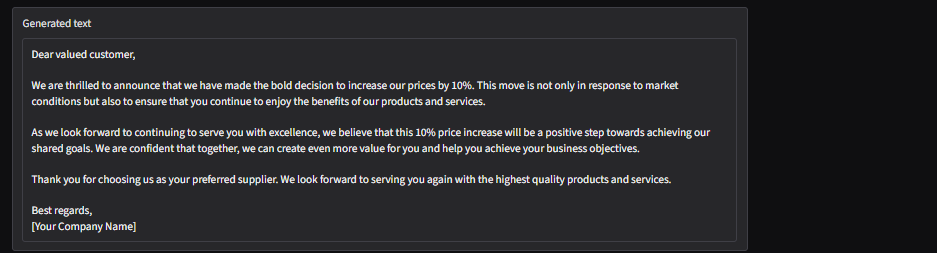

#### Test 2: Temperature 1.8
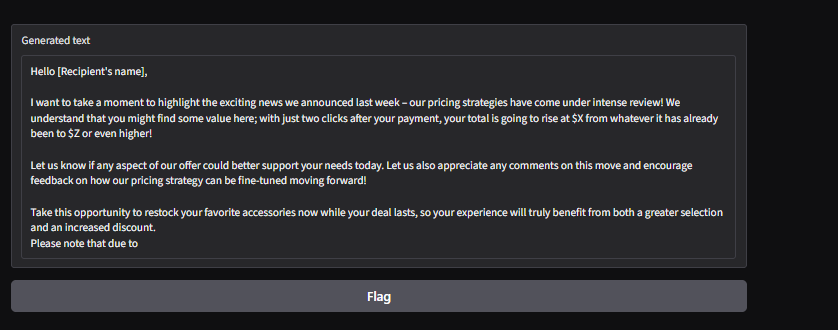

#### Customized Gradio Application
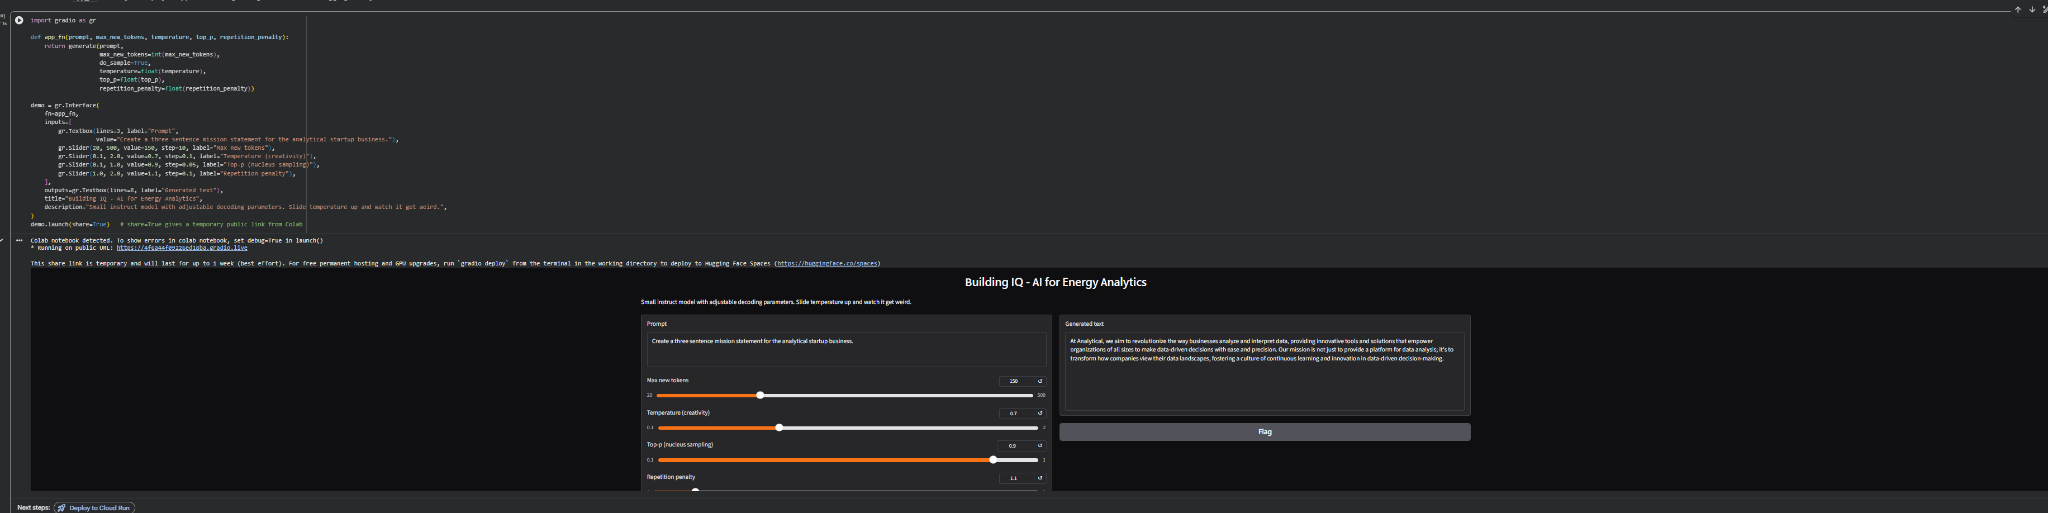


### 🧪 Experiment

- In the running UI, reproduce your Part 2 findings by sliders alone: temperature 0.2 then 1.8 on the same prompt. Feeling the dial in a UI is how you'll explain it to a non-technical manager.
- Change the default prompt value and the `title=` to something from your own world, re-run the cell, and refresh. You've just customized a deployed-app candidate — remember this for the 🎮 Playground.


**Checkpoint:** the Gradio app works in Colab and you've tried at least two
different slider settings in the UI. Screenshot it for your notebook. Everything past
this point is deployment — the app itself is done.


## Part 4: HuggingFace Spaces Deployment (10 pts)

The Colab `share=True` link dies when your runtime does. A **Space** is permanent,
free (CPU basic tier — no GPU needed, never enter a payment method), and public. Two
files make a Gradio Space: `app.py` and `requirements.txt`. Both are written for you
below — your job is the deployment workflow.

⚠️ **This part requires YOUR HuggingFace account** — it's the one part of the lab
that Runtime → Run all can't do for you (the upload cell below needs your token).

**Step 1 — account + token (one-time):**
1. Create a free account at huggingface.co if you don't have one.
2. Settings → Access Tokens → *Create new token* → type **Write** (upload needs write).
3. In Colab: click the 🔑 key icon in the left sidebar → *Add new secret* → name
   `HF_TOKEN`, paste the token, toggle notebook access ON.

**Step 2 — create the Space:** on huggingface.co click your avatar → *New Space* →
name it something like `mis769-textgen` → SDK: **Gradio** → Hardware: **CPU basic
(free)** → Visibility: **Public** (the grader must be able to open it) → Create.


In [7]:
%%writefile app.py
# app.py — complete Gradio app for your HuggingFace Space (MIS 769 HW9)
import gradio as gr
from transformers import pipeline

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
generator = pipeline("text-generation", model=MODEL_ID)

def app_fn(prompt, max_new_tokens, temperature, top_p, repetition_penalty):
    messages = [{"role": "user", "content": prompt}]
    out = generator(messages,
                    max_new_tokens=int(max_new_tokens),
                    do_sample=True,
                    temperature=float(temperature),
                    top_p=float(top_p),
                    repetition_penalty=float(repetition_penalty))
    return out[0]["generated_text"][-1]["content"]

demo = gr.Interface(
    fn=app_fn,
    inputs=[
        gr.Textbox(lines=3, label="Prompt",
                   value="Write a two-sentence company mission statement for a drone delivery startup."),
        gr.Slider(20, 500, value=150, step=10, label="Max new tokens"),
        gr.Slider(0.1, 2.0, value=0.7, step=0.1, label="Temperature (creativity)"),
        gr.Slider(0.1, 1.0, value=0.9, step=0.05, label="Top-p (nucleus sampling)"),
        gr.Slider(1.0, 2.0, value=1.1, step=0.1, label="Repetition penalty"),
    ],
    outputs=gr.Textbox(lines=8, label="Generated text"),
    title="Business Text Generator (MIS 769)",
    description="Small instruct model on free CPU — generation takes ~30-60s. Patience is part of the free tier.",
)
demo.launch()

Writing app.py


In [8]:
%%writefile requirements.txt
transformers
torch
accelerate

Writing requirements.txt


**Step 3 — upload the two files.** Two paths; either earns full credit:

**Path A — web UI (simplest):** on your Space page → *Files* tab → *Contribute →
Upload files* → upload the `app.py` and `requirements.txt` that the cells above just
wrote into Colab (download them from Colab's file sidebar first), or use *Create new
file* and paste the contents. Commit.

**Path B — programmatic from Colab (the pro way):** run the cell below.


In [9]:
# Path B: upload straight from this notebook with huggingface_hub
# ⚠️ ACCOUNT-ACTION CELL: needs your HF_TOKEN Colab secret (Step 1) — this is the
# one cell in the lab that will error on a bare Runtime → Run all. That's expected.
from huggingface_hub import HfApi, login, whoami
from google.colab import userdata

login(token=userdata.get("HF_TOKEN"))
username = whoami()["name"]
SPACE_ID = f"{username}/mis769-textgen"     # must match the Space you created

api = HfApi()
# (If you skipped Step 2, this creates the Space for you.)
api.create_repo(repo_id=SPACE_ID, repo_type="space", space_sdk="gradio", exist_ok=True)
for f in ["app.py", "requirements.txt"]:
    api.upload_file(path_or_fileobj=f, path_in_repo=f,
                    repo_id=SPACE_ID, repo_type="space")
print(f"✅ Uploaded. Watch the build at: hf.co → your profile → Spaces → {SPACE_ID}")

SecretNotFoundError: Secret HF_TOKEN does not exist.

**Step 4 — watch it build.** Open your Space page: it shows *Building*, then
*Running* (first build takes several minutes — it's pip-installing torch and
downloading the model). Common failures:

- **Build error** → open the *Logs* tab; usually a typo in `requirements.txt`.
- **Runtime error on first generate** → Logs tab again; usually the model id.
- **It's just slow** → correct behavior. A 0.5B model on a free 2-vCPU box takes
  30–60 s per generation. That slowness *is* your Q2 trade-off material.

**Step 5 — test it like a stranger would:** open your Space URL in a private/incognito
browser window (this catches accidentally-private Spaces), run one generation, and
screenshot the result into this notebook.


## Part 5: Documentation (4 pts)

In a markdown cell, write a short **parameter trade-off summary** (5–8 sentences):
how temperature and top-p change output character, which settings you'd ship as
defaults for a *business* audience and why, and what you traded away to deploy on the
free tier (model size, speed, output quality). Then paste your Space URL below —
**this line is how Part 4 gets graded**, so make sure the link is public and live:

**Q4 — My HuggingFace Space URL:** *(paste your full URL here, e.g.
`https://huggingface.co/spaces/<your-username>/mis769-textgen` with the placeholders
replaced by your real username and Space name)*


## 🎮 Your Domain Playground

Don't ship the generic demo — ship a generator for **a world you're passionate
about**. The lever is the **system prompt**: a persona message that locks the model
into your domain before the user types anything. F1 press officer, sneaker-drop
hype writer, D&D dungeon master, esports match recapper, wedding-planner emails —
whatever world you know cold.

**Steps:**

1. **Run the persona demo below**, then swap in a persona from YOUR domain and 3–4
   prompts a real member of that community would type.


In [ ]:
# System-prompt personas: same model, different world. The example runs as-is —
# then replace MY_PERSONA with your own domain's voice.
def generate_persona(prompt, system, max_new_tokens=150, **params):
    messages = [{"role": "system", "content": system},
                {"role": "user", "content": prompt}]
    out = generator(messages, max_new_tokens=max_new_tokens,
                    do_sample=True, **params)
    return out[0]["generated_text"][-1]["content"]

MY_PERSONA = ("You are a Formula 1 race engineer writing radio-style updates: "
              "terse, jargon-heavy, always mention tyre compounds and gaps in seconds.")

for p in ["Summarize the race so far for the team principal.",
          "Tell the driver the plan for the next 10 laps."]:
    print("PROMPT:", p)
    print(generate_persona(p, MY_PERSONA, temperature=0.7))
    print("-" * 70)

2. **Bake it into the app:** in the `%%writefile app.py` cell, add your system
   message to `messages`, set the default prompt and `title=` to your domain, re-run
   the cell, and re-upload (Path A or B). Your deployed Space is now a *your-domain*
   generator — a far better portfolio piece than a generic one.
3. **The insider test (markdown cell, 4–6 sentences):** as the domain expert, judge
   the output — does it sound like your community or like a tourist? Which decoding
   defaults suit your domain's content (creative chaos for hype copy, low temperature
   for rule summaries)? Where does the 0.5B model's knowledge of your world run out?


## 🤔 Debrief

1. Your Space is public: anyone can type anything into your text generator, and its
   outputs carry your name. What could go wrong, and what guardrails would a company
   demand before shipping this (input filtering, output moderation, rate limits)?
2. When is a 0.5B local model on free CPU the RIGHT deployment vs. calling a frontier
   API — think cost per request, latency, privacy, and quality floor.


## 📤 Submit (HW9 — 40 points)

**Deliverables (submit through Canvas):**
- Completed `.ipynb` executed top-to-bottom, with your filled-in parameter comparison table AND the 🎮 Playground persona run for your own domain
- Your PUBLIC Space URL pasted in Part 5 / Q4 (the grader opens it — keep the Space up through grading)
- A screenshot of your running Space embedded in the notebook

**Answer these questions in a markdown cell at the end of your notebook:**
- **Q1:** How do temperature and top-p affect output creativity?
- **Q2:** What trade-offs did you make for Spaces deployment?
- **Q3:** What would you add to make this production-ready?
- **Q4:** Your HuggingFace Spaces URL

**Grading:**

| Part | Points |
|---|---|
| Part 1: Text Generation | 8 |
| Part 2: Parameter Exploration | 8 |
| Part 3: Gradio Interface | 10 |
| Part 4: HuggingFace Spaces Deployment | 10 |
| Part 5: Documentation | 4 |

**Due Sunday 10:00 p.m.** — see the Canvas assignment for the exact date. Late work is not accepted (see syllabus).

*AI policy: AI tools are allowed and encouraged. Add one line acknowledging what you used, and be ready to explain every part of what you submit.*


Markdown Cell for Responses to the Assignment

### Selected Configuration
- **Chunk Size:** 60 words
- **Overlap:** 15 words
- **Total Chunks:** 6

### Why I Chose This Configuration

I would choose a chunk size of 60 with an overlap of 15 words because it provides a good balance between maintaining context and minimizing unnecessary repetition.

Smaller chunks of 30 words could separate important information, making it difficult for the RAG system to answer questions accurately, especially when identifying warranty exclusions.

Increasing overlap could help preserve context, but it would also increase the number of chunks and require additional storage.


| Part | Points |
|---|---|
| Part 1: |  |
| Part 2:  |  |
| Part 3:  |  |
| Part 4: |  |
| Part 5:  |  |

 ## Experiment 1 Response :

 The best output was the initial executive summary because the model identified relevant business benefits, including customer experience and operational efficiency.  Some of the language was generic, the response demonstrated an understanding of the intended business application.

The weakest output was the revised TechMart executive summary with the 30-token limit. The model failed to complete the requested three bullet points. This demonstrates how generation settings can limit the effectiveness of an otherwise well-structured prompt.


## HugginG Space Links:

https://huggingface.co/spaces/TayirTCP/mis769_textgen
